# Group 5420：shuffled CV 会把次日股票预测的 AUC 高估多少？

**主 notebook**：从上往下运行，就能完整复现目前的全部结果（约 4 分钟）。作者：Jin、Qidi（Yixun 负责关键图和误差分析）。

| 本 notebook 的第几步 | 做什么 | 代码文件 | 检查文件 |
|---|---|---|---|
| 第 1 步 | 读数据、检查数据 | `src/step1_load_data.py` | — |
| 第 2 步 | 造 23 个特征和标签 | `src/step2_features.py` | `tests/test_step2_no_lookahead.py`（防偷看） |
| 第 3 步 | 切分：每个测试年的训练/测试集、三种 CV、bootstrap | `src/step3_splits.py` | `tests/test_step3_splits.py` |
| 第 4 步 | 模型 + 一个测试年的结果 | `src/step4_models.py`、`src/step5_evaluate.py` | `tests/test_step5_evaluate.py` |
| 第 5 步 | 12 个测试年 | `src/step5_evaluate.py` | — |
| 第 6 步 | 12 年汇总 + 关键图 | `src/step6_summary.py` | — |

所有定死的设置（种子、模型配置）都在 `src/config.py`。

**第一次运行前**：VS Code 右上角 **Select Kernel** → 选 **Python (finalpaper)**。

In [1]:
import sys
import numpy as np
import pandas as pd

from src.config import SEED, SCHEMES, LR_FIXED_C
print("Python:", sys.executable)   # 应该以 envs/finalpaper/bin/python 结尾
print("SEED =", SEED)

Python: /opt/anaconda3/envs/finalpaper/bin/python
SEED = 5420


## 第 1 步：读数据、检查数据
预期：514,075 行，100 只股票，没有重复，没有非正价格，没有缺失值。

In [2]:
from src.step1_load_data import load_prices, check_prices

raw = load_prices()          # 读 data/NASDAQ100_Historical_Data.csv，按 Ticker、Date 排序
checks = check_prices(raw)

Total rows:        514,075
Tickers:           100
Date range:        2000-01-03 to 2026-02-18
Duplicate (Ticker, Date) rows: 0
Rows with a non-positive price: 0
Missing values:    0

Per-ticker start / end dates (sorted by start date):
             start         end  rows
Ticker                              
AAPL    2000-01-03  2026-02-18  6571
ADBE    2000-01-03  2026-02-18  6571
ADI     2000-01-03  2026-02-18  6571
ADP     2000-01-03  2026-02-18  6571
ADSK    2000-01-03  2026-02-18  6571
AEP     2000-01-03  2026-02-18  6571
AMAT    2000-01-03  2026-02-18  6571
AMD     2000-01-03  2026-02-18  6571
AMGN    2000-01-03  2026-02-18  6571
AMZN    2000-01-03  2026-02-18  6571
ASML    2000-01-03  2026-02-18  6571
BIIB    2000-01-03  2026-02-18  6571
BKNG    2000-01-03  2026-02-18  6571
BKR     2000-01-03  2026-02-18  6571
CCEP    2000-01-03  2026-02-18  6571
CDNS    2000-01-03  2026-02-18  6571
CMCSA   2000-01-03  2026-02-18  6571
COST    2000-01-03  2026-02-18  6571
CPRT    2000-01-03  2026

## 第 2 步：标签和 23 个特征
特征 = Kaggle 比赛文档里的 27 个指标，去掉 4 个和收益率完全重复的（momentum_10d/20d、roc_5/10）。
标签 `target` = 1 表示第二天复权收盘价更高。
预期：491,772 行，约 50.58% 是上涨日。

In [3]:
from src.step2_features import FEATURES, features_by_ticker, build_model_table

table = build_model_table(raw)
print(f"{len(FEATURES)} 个特征，{len(table):,} 行，{100 * table['target'].mean():.2f}% 上涨日")
table.head()

23 个特征，491,772 行，50.58% 上涨日


,Ticker,Date,return_1d,return_5d,return_10d,return_20d,sma_ratio_5,sma_ratio_10,sma_ratio_20,sma_ratio_50,...,volatility_10d,volatility_20d,volatility_60d,volume_sma_ratio_10,volume_sma_ratio_20,daily_range,avg_range_10d,high_low_ratio,atr_14,target
199,AAPL,2000-10-16,-0.030303,-0.030303,-0.111111,-0.648352,1.032258,0.993789,0.608944,0.455840,...,0.958468,1.978783,1.271015,0.763957,0.671539,0.105263,0.093531,1.105263,0.166713,0.0
200,AAPL,2000-10-17,-0.062500,-0.032258,-0.090909,-0.666667,0.974026,0.940439,0.605449,0.432526,...,0.918769,1.977105,1.265593,0.647046,0.486102,0.111111,0.092142,1.114286,0.173062,0.0
201,AAPL,2000-10-18,0.000000,0.034483,-0.142857,-0.670330,0.967742,0.955414,0.645161,0.437573,...,0.838964,1.973469,1.263342,0.962496,0.657839,0.138889,0.098888,1.151515,0.170621,0.0
202,AAPL,2000-10-19,-0.066667,-0.066667,-0.151515,-0.670588,0.915033,0.906149,0.641466,0.413589,...,0.853888,1.973582,1.268274,1.619882,1.143188,0.058824,0.091950,1.060606,0.176953,1.0
203,AAPL,2000-10-20,0.035714,-0.121212,-0.121212,-0.628205,0.973154,0.950820,0.703883,0.433742,...,0.889545,1.987192,1.267555,0.834661,0.598883,0.057143,0.090164,1.058824,0.163151,1.0


### 2a. 防偷看测试：先手动看一个例子
规则：第 t 天的特征只能用到第 t 天为止的价格。
做法：把 t 之后的每个价格、成交量都乘以 0.5 到 2 之间的随机数，然后重新计算特征。t 当天及之前的特征必须**一模一样**。

In [4]:
from tests.test_step2_no_lookahead import scramble_after   # 正式测试用的同一个打乱函数

cutoff = "2011-12-30"
original = features_by_ticker(raw)[FEATURES]
changed_raw, future = scramble_after(raw, cutoff, SEED)
recomputed = features_by_ticker(changed_raw)[FEATURES]

diff = (recomputed - original).abs()
print("t 及之前的行：", (~future).sum(), "| 特征的最大变化：", diff[~future].max().max())
print("t 之后的行：  ", future.sum(), "| 特征的最大变化：", diff[future].max().max())

t 及之前的行： 196104 | 特征的最大变化： 0.0
t 之后的行：   317971 | 特征的最大变化： 57.331622775778136


In [5]:
# 苹果在截止日前后：2011-12-30 及之前完全一样，之后都变了
aapl = (raw["Ticker"] == "AAPL") & raw["Date"].between("2011-12-27", "2012-01-05")
pd.DataFrame({
    "日期": raw.loc[aapl, "Date"].dt.date,
    "价格（原始）": raw.loc[aapl, "Adj Close"],
    "价格（打乱后）": changed_raw.loc[aapl, "Adj Close"].round(2),
    "return_1d（原始）": original.loc[aapl, "return_1d"].round(5),
    "return_1d（打乱后）": recomputed.loc[aapl, "return_1d"].round(5),
})

,日期,价格（原始）,价格（打乱后）,return_1d（原始）,return_1d（打乱后）
3015,2011-12-27,12.18,12.18,0.00828,0.00828
3016,2011-12-28,12.06,12.06,-0.00985,-0.00985
3017,2011-12-29,12.14,12.14,0.00663,0.00663
3018,2011-12-30,12.14,12.14,0.00000,0.00000
3019,2012-01-03,12.32,19.08,0.01483,0.57179
3020,2012-01-04,12.39,8.19,0.00568,-0.57101
3021,2012-01-05,12.53,11.36,0.01130,0.38756


### 2b. 防偷看正式测试
测 4 个截止日、全部股票，另外确认测试能抓到一个故意偷看未来的特征。5 行都应该是 **PASSED**。改过 `step2_features.py` 后要重跑这一格。

In [6]:
!{sys.executable} -m pytest -v tests/test_step2_no_lookahead.py

============================= test session starts ==============================
platform darwin -- Python 3.11.18, pytest-9.2.0, pluggy-1.7.0 -- /opt/anaconda3/envs/finalpaper/bin/python
cachedir: .pytest_cache
rootdir: /Users/wangjin/Desktop/26Fall/ESE542/542_finalpaper
configfile: pytest.ini
plugins: platformdirs-4.14.5, anyio-4.16.0
collecting ... 

collected 5 items                                                              

tests/test_step2_no_lookahead.py::test_features_ignore_future_prices[2005-06-30] 

PASSED [ 20%]
tests/test_step2_no_lookahead.py::test_features_ignore_future_prices[2011-12-30] 

PASSED [ 40%]
tests/test_step2_no_lookahead.py::test_features_ignore_future_prices[2018-03-15] 

PASSED [ 60%]
tests/test_step2_no_lookahead.py::test_features_ignore_future_prices[2023-12-29] 

PASSED [ 80%]
tests/test_step2_no_lookahead.py::test_check_catches_a_leaky_feature 

PASSED [100%]

============================== 5 passed in 3.19s ===============================


## 第 3 步：切分
- **外层切分**：测试年 Y → 训练用 Y 之前的所有天，**去掉最后一天**（它的标签用到了 Y 的第一天）；测试用 Y 全年。
- **内层三种 CV**（只在训练部分里做）：
  1. shuffled：每一**行**随机分到 5 折；
  2. 按日期分组：每一**天**随机分到 5 折，同一天的所有股票在同一折；
  3. walk-forward：训练部分的最后 5 年，每年当一次验证，只用更早的数据训练，同样去掉最后一天。
- **bootstrap**：每个测试年的交易日有放回地抽 1,000 次。只抽一次，所有模型、所有方式共用。

In [7]:
from src.step3_splits import TESTS, trading_days, split, assign_folds_and_bootstrap, inner_folds

days = trading_days(table)                       # 所有交易日
boot = assign_folds_and_bootstrap(table, days)   # 给每行加上两种折号，并返回 bootstrap 抽样

dev, test_rows = split(table, days, 2012)
print(f"测试年 2012 → 训练 {dev['Date'].min().date()} 到 {dev['Date'].max().date()}（{len(dev):,} 行），"
      f"测试 {test_rows['Date'].min().date()} 到 {test_rows['Date'].max().date()}（{len(test_rows):,} 行）")
print("2012 年的 bootstrap 抽样：", boot[2012].shape, "（1,000 次 × 交易日数）")

测试年 2012 → 训练 2000-10-16 到 2011-12-29（179,932 行），测试 2012-01-03 到 2012-12-31（18,791 行）
2012 年的 bootstrap 抽样： (1000, 250) （1,000 次 × 交易日数）


In [8]:
# 测试年 2012 的 15 个内层折
rows = []
for scheme in SCHEMES:
    for k, (tr, va) in enumerate(inner_folds(table, days, 2012, scheme)):
        va_dates = table.loc[va, 'Date']
        rows.append({'方式': scheme, '折': k, '训练行数': len(tr), '验证行数': len(va),
                     '验证日期': f"{va_dates.min().date()} 到 {va_dates.max().date()}",
                     '验证日也出现在训练里（%）': round(100 * va_dates.isin(set(table.loc[tr, 'Date'])).mean(), 1)})
pd.DataFrame(rows)

,方式,折,训练行数,验证行数,验证日期,验证日也出现在训练里（%）
0,shuffled,0,144093,35839,2000-10-16 到 2011-12-29,100.0
1,shuffled,1,143944,35988,2000-10-16 到 2011-12-29,100.0
2,shuffled,2,143933,35999,2000-10-16 到 2011-12-29,100.0
3,shuffled,3,143989,35943,2000-10-16 到 2011-12-29,100.0
4,shuffled,4,143769,36163,2000-10-16 到 2011-12-29,100.0
5,date_grouped,0,143552,36380,2000-10-23 到 2011-12-28,0.0
6,date_grouped,1,145573,34359,2000-10-18 到 2011-12-16,0.0
7,date_grouped,2,142578,37354,2000-10-16 到 2011-12-22,0.0
8,date_grouped,3,144018,35914,2000-10-24 到 2011-12-20,0.0
9,date_grouped,4,144007,35925,2000-10-17 到 2011-12-29,0.0


shuffled 的验证日 100% 也出现在训练里，这正是我们要测量的"同一天泄露"；另外两种方式是 0%。

### 3b. 切分的正式检查（全部应通过）

In [9]:
!{sys.executable} -m pytest -q tests/test_step3_splits.py

.

...

.

...

.

..

... (36 outputs left out)

.

.

.

...                   [100%]
54 passed in 25.29s


## 第 4 步：模型，以及一个测试年（2018）的结果
固定配置（`src/config.py`，在训练任何模型之前就定死了）：
- **逻辑回归**：把每个特征截到训练折的 1%–99% 分位数 → 标准化 → L2 逻辑回归，C = 1。
- **LightGBM**：num_leaves = 32，300 棵树，学习率 0.05（后面用）。

结果的含义：
- `cv_auc` = 该方式 5 折 AUC 的平均（估计值）；
- `test_auc` = 用整个训练部分重新训练，在测试年上的 AUC（真实值）；
- `[test_lo, test_hi]` = 真实值的 95% bootstrap 区间；
- `error` = cv_auc − test_auc。

In [10]:
from src.step4_models import logistic
from src.step5_evaluate import cv_auc, test_auc

YEAR = 2018
make = lambda: logistic(LR_FIXED_C)
auc, lo, hi = test_auc(table, days, boot, YEAR, make)
one_year = pd.DataFrame({s: {'cv_auc': cv_auc(table, days, YEAR, s, make)} for s in SCHEMES}).T.assign(test_auc=auc, test_lo=lo, test_hi=hi)
one_year['error'] = one_year['cv_auc'] - one_year['test_auc']
one_year.round(4)

,cv_auc,test_auc,test_lo,test_hi,error
shuffled,0.5264,0.5157,0.4934,0.5395,0.0107
date_grouped,0.5233,0.5157,0.4934,0.5395,0.0076
walk_forward,0.5187,0.5157,0.4934,0.5395,0.0030


### 4a. 交叉验证：只用 sklearn 自带工具，把上面的数重算一遍
不经过我们自己写的评估函数，下表的差值都应该是 0。

In [11]:
from sklearn.model_selection import PredefinedSplit, cross_val_score
from sklearn.metrics import roc_auc_score

dev, test_rows = split(table, days, YEAR)
X_dev, y_dev = dev[FEATURES].to_numpy(), dev['target'].to_numpy()

# CV 估计：用 sklearn 的 cross_val_score，折号和上面相同
check = {}
for scheme, col in [('shuffled', 'fold_shuffled'), ('date_grouped', 'fold_date')]:
    check[scheme] = cross_val_score(make(), X_dev, y_dev, cv=PredefinedSplit(dev[col].to_numpy()), scoring='roc_auc').mean()

# 真实 AUC 和区间：用 sklearn 的 roc_auc_score；bootstrap = 每行的权重是它那一天被抽中的次数
p = make().fit(X_dev, y_dev).predict_proba(test_rows[FEATURES].to_numpy())[:, 1]
y_test = test_rows['target'].to_numpy()
day_pos = days[(days >= f'{YEAR}-01-01') & (days <= f'{YEAR}-12-31')].get_indexer(test_rows['Date'])
boot_aucs = [roc_auc_score(y_test, p, sample_weight=c[day_pos]) for c in boot[YEAR]]
sk_lo, sk_hi = np.percentile(boot_aucs, [2.5, 97.5])

pd.DataFrame({
    '我们的代码': [one_year.loc['shuffled', 'cv_auc'], one_year.loc['date_grouped', 'cv_auc'], auc, lo, hi],
    '只用 sklearn': [check['shuffled'], check['date_grouped'], roc_auc_score(y_test, p), sk_lo, sk_hi],
}, index=['cv_auc shuffled', 'cv_auc date_grouped', 'test_auc', 'test_lo', 'test_hi']).assign(
    差值=lambda d: d['我们的代码'] - d['只用 sklearn']).round(6)

,我们的代码,只用 sklearn,差值
cv_auc shuffled,0.526431,0.526431,-0.0
cv_auc date_grouped,0.523285,0.523285,0.0
test_auc,0.515708,0.515708,0.0
test_lo,0.493359,0.493359,0.0
test_hi,0.539495,0.539495,0.0


### 4b. 安慰剂检验：把标签换成随机抛硬币
这时什么都预测不了，三种方式的 AUC **都应该约等于 0.5**。如果某种方式明显高于 0.5，说明流程本身有泄露。

In [12]:
placebo = table.copy()
placebo['target'] = np.random.default_rng(0).integers(0, 2, len(placebo)).astype(float)
pd.Series({s: cv_auc(placebo, days, YEAR, s, make) for s in SCHEMES}, name='随机标签下的 cv_auc').round(4)

shuffled        0.5013
date_grouped    0.5014
walk_forward    0.5004
Name: 随机标签下的 cv_auc, dtype: float64

### 4c. 评估代码的正式检查（全部应通过）

In [13]:
!{sys.executable} -m pytest -q tests/test_step5_evaluate.py

..                                                                       [100%]
2 passed in 1.23s


## 第 5 步：逻辑回归，12 个测试年（2012–2023）
结果每跑完一年就存进 `results/results.csv`；已经算过的年份会跳过。第一次运行约 3 分钟。
下表是每一年的误差（cv_auc − test_auc）。

In [14]:
from src.step5_evaluate import run_years

lr_results = run_years(table, days, boot, 'logistic', make)
lr_results.pivot(index='year', columns='scheme', values='error')[list(SCHEMES)].round(4)

scheme,shuffled,date_grouped,walk_forward
year,,,
2012,0.0196,0.0155,0.0078
2013,0.0023,-0.0020,-0.0081
2014,0.0091,0.0048,0.0000
2015,0.0019,-0.0021,-0.0085
2016,0.0109,0.0072,0.0012
2017,0.0103,0.0071,0.0012
2018,0.0107,0.0076,0.0030
2019,0.0090,0.0064,0.0005
2020,0.0184,0.0159,0.0104


## 第 6 步：12 年汇总和关键图（第一版）
- `mean_error ± ci_95`：12 年误差的平均和 95% t 区间。⚠️ 这里把 12 年当作互相独立，但各年的训练数据大量重叠，所以这个区间偏窄，论文里要说明。
- `years_outside_noise`：估计值落在测试年 bootstrap 区间之外的年数（教授的标准：落在区间内就算噪声）。
- 两两比较：同一年里两种方式的误差相减，测试年本身的噪声会抵消掉。

In [15]:
from src.step6_summary import summarize, key_figure

err, by_scheme, paired = summarize(lr_results)
display(by_scheme.round(4), paired.round(4))

,mean_error,ci_95,years_overstated,years_outside_noise
scheme,,,,
shuffled,0.0116,0.0045,12,1
date_grouped,0.0081,0.0045,10,0
walk_forward,0.0020,0.0045,9,0


,mean_diff,ci_95,years_positive
shuffled - walk_forward,0.0097,0.0008,12.0
date_grouped - walk_forward,0.0061,0.0006,12.0
shuffled - date_grouped,0.0036,0.0004,12.0


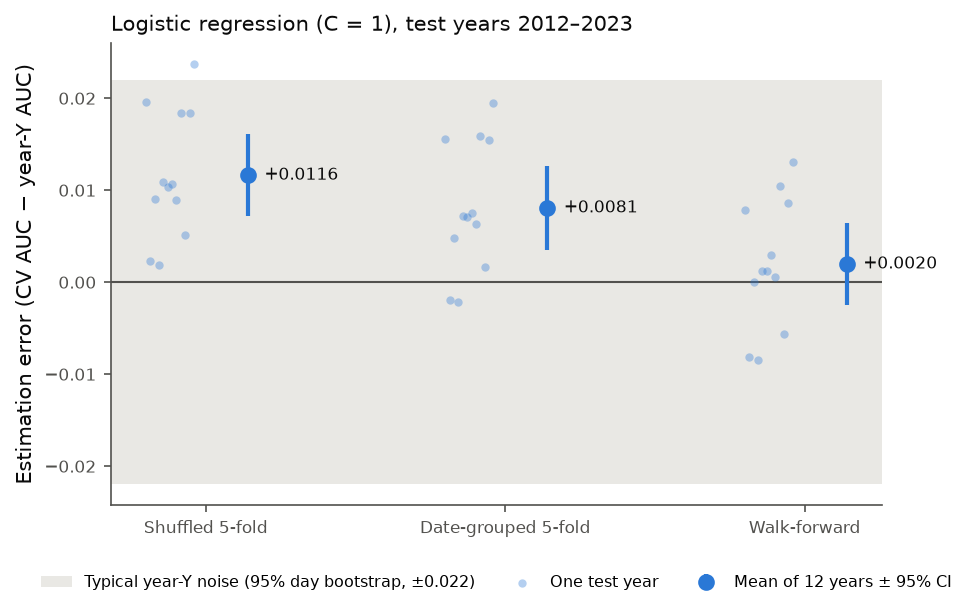

In [16]:
fig = key_figure(lr_results, 'Logistic regression (C = 1), test years 2012–2023',
                 path='figures/key_figure_v1_logistic.png')